# Author Gender Analysis

## 1. Libraries and Data

In [1]:
# Libraries
import pickle
import statistics
import matplotlib.pyplot as plt
import re
import pandas as pd
from collections import Counter
import numpy as np
from collections import OrderedDict
import math
from datetime import date
from datetime import datetime, timedelta
from scipy.stats import median_test
import statistics
import matplotlib.dates as mdates
from adjustText import adjust_text

In [2]:
with open('../data/aus/clean/aus_deidentified_min_fields.pkl', 'rb') as f:
    aus = pickle.load(f, encoding="utf-8")
    
with open('../data/canada/clean/can_deidentified_min_fields.pkl', 'rb') as f:
    can = pickle.load(f, encoding="utf-8")

In [3]:
df = pd.DataFrame(aus).T.reset_index().rename(columns={'index': 'ID'})[['ID', 'date', 'signatures', 'gender']]

print(df)

        ID       date signatures  gender
0        1 2016-10-04        336    male
1        2 2016-10-04         21    male
2        3 2016-10-04         69    male
3        7 2016-10-04         18    male
4        9 2016-10-04         32  female
...    ...        ...        ...     ...
3901  7333 2025-03-26         14    male
3902  7336 2025-03-26         30    male
3903  7337 2025-03-26         84  female
3904  7339 2025-03-26       5447    male
3905  7341 2025-03-26        110    male

[3906 rows x 4 columns]


In [4]:
# percentage of unknown/other gender classifications
len(df[df['gender'] == 'unknown/other'])/len(df)*100

0.6656426011264721

In [5]:
# https://www.aph.gov.au/Parliamentary_Business/Committees/Joint/Public_Accounts_and_Audit/DFATcrisismanagement/Report_494_Inquiry_into_the_Department_of_Foreign_Affairs_and_Trades_crisis_management_arrangem/C_Timeline_of_key_events
# using dates from above to filter covid-era petitions
covid_start = datetime(2020, 3, 18, 0, 0, 0) # declaration of biosecurity emergency in Aus
#covid_end = datetime(2021, 11, 1, 0, 0, 0) # borders opened for fully vaccinated Australians to travel   
covid_end = datetime(2022, 2, 21, 0, 0, 0) # borders open to all fully vaccinated inbound travellwer - 21/02/2022

In [6]:
## Canada

# Start date: https://www.publicsafety.gc.ca/cnt/trnsprnc/brfng-mtrls/prlmntry-bndrs/20210907/05-en.aspx
# Restriction on people flying in
# End date: https://www.canada.ca/en/public-health/services/diseases/coronavirus-disease-covid-19/testing-screening-contact-tracing/summary-data-travellers.html
# Dropping of travel restrictions

covid_start_can = datetime(2020, 3, 18, 0, 0, 0)
covid_end_can = datetime(2022, 10, 1, 0, 0, 0)

### Preparing dictionaries and data frames

In [7]:
def creating_dfs_dicts(epets):
    
    # Chronological order data frame
    chron_df = pd.DataFrame(epets).T.reset_index().rename(columns={'index': 'id'}).sort_values(by = ['date', 'id'], ascending = [True, True])
    gen_df = chron_df[['id', 'signatures', 'gender']] # CHRONOLOGICAL ORDER - tie-break with ID
    
    # Descending order by signatures, tie-break by date, then tie-break with ID (lower ID first)
    gen_sig_df = chron_df.copy()
    gen_sig_df = gen_sig_df.sort_values(by = ['signatures', 'date', 'id'], ascending = [False, True, True]) # CHANGE BACK TO FALSE, TRUE, TRUE
    gen_sig_df = gen_sig_df[['id', 'signatures', 'gender']]
    gen_dict_sorted = dict(zip(gen_sig_df[['id', 'gender']].iloc[:, 0], gen_sig_df[['id', 'gender']].iloc[:, 1]))
    
    gen_date_sig = pd.DataFrame(epets).T.reset_index()[['index', 'signatures', 'gender', 'date']].rename(columns={'index': 'id'})
    df_gds_wide = gen_date_sig.pivot(index=['date', 'id'], columns='gender', values='signatures').reset_index()
    
    
    # For each date in the dataset, sum the number of signatures in each gender category with a 0 for absent gender appearances
    # Ascending order by date - Chronological order
    grouped = gen_date_sig.groupby(['date', 'gender'])['signatures'].sum()
    all_stores = gen_date_sig['date'].unique()
    all_categories = gen_date_sig['gender'].unique()
    full_index = pd.MultiIndex.from_product([all_stores, all_categories], names=['date', 'gender'])
    result = grouped.reindex(full_index, fill_value=0).reset_index()
    pivoted = result.pivot(index="date", columns="gender", values="signatures").reset_index() #.rename(columns = {'gender': 'index'})
    pivoted = pivoted.sort_values(by = 'date', ascending = True)
    

    # FIELDS COME FROM THE CHRONOLOGICAL DF BECAUSE THIS IS ORDER BY DATE THEN ID
    epet_dates = list(chron_df['date'])
    sig_list_chron = list(chron_df['signatures'])
    
    return chron_df, gen_df, gen_sig_df, gen_dict_sorted, gen_date_sig, df_gds_wide, pivoted, epet_dates, sig_list_chron

In [8]:
chron_df_aus, gen_df_aus, gen_sig_df_aus, gen_dict_sorted_aus, gen_date_sig_aus, df_gds_wide_aus, pivoted_aus, epet_dates_aus, sig_list_chron_aus = creating_dfs_dicts(aus)


In [9]:
chron_df_can, gen_df_can, gen_sig_df_can, gen_dict_sorted_can, gen_date_sig_can, df_gds_wide_can, pivoted_can, epet_dates_can, sig_list_chron_can = creating_dfs_dicts(can)


## 2. Summary Stats

In [10]:
#len(gen_df_aus[gen_df_aus['gender'] == 'male'])
#len(gen_df_aus[gen_df_aus['gender'] == 'female'])
#len(gen_df_aus[gen_df_aus['gender'] == 'unknown/other'])

In [11]:
def summary_stats(gen_df):
    print('Average signatures per petition')
    print(np.divide(gen_df.groupby('gender').sum()['signatures'], gen_df.groupby('gender').count()['signatures']))
    print()
    
    print('Median signatures per petition')
    print(gen_df.groupby('gender').median()['signatures'])
    print()

    print('Max signatures')
    print(gen_df.groupby('gender').max()['signatures'])

In [12]:
summary_stats(gen_sig_df_aus)

Average signatures per petition
gender
female           2121.130779
male             1483.343618
unknown/other    5884.192308
Name: signatures, dtype: object

Median signatures per petition
gender
female           48.0
male             23.0
unknown/other    31.0
Name: signatures, dtype: object

Max signatures
gender
female           309829
male             501128
unknown/other    148182
Name: signatures, dtype: object


In [13]:
summary_stats(gen_sig_df_can)

Average signatures per petition
gender
female           4016.311159
male             3585.902922
unknown/other    2104.878049
Name: signatures, dtype: object

Median signatures per petition
gender
female           819.5
male             758.0
unknown/other    604.0
Name: signatures, dtype: object

Max signatures
gender
female           387487
male             230905
unknown/other     22283
Name: signatures, dtype: object


## 3. Gender-Signature Plots

### 3.1 Gender in Top R% Petitions

In [14]:
def percentage_slicer(sig_dict, r):    
    slicer_val = int(len(sig_dict.keys())*r/100)
    
    return dict(list(sig_dict.items())[:slicer_val])

def slicer_dict_creator(cat_key_dict):
    import numpy as np
    from collections import Counter
    
    output_dict = {}
    for i in range(1,101):
        sliced_dict = percentage_slicer(cat_key_dict, i)
        l = len(sliced_dict)    
        values = sliced_dict.values()
        value_counts = Counter(values)
        cat_props = {k:v/l for k,v in value_counts.items()}
            
        output_dict[i] = cat_props
    
    return output_dict
 
def sliced_gen_df_pipeline(gen_dict_sorted):
    sliced_gen = slicer_dict_creator(gen_dict_sorted)
    sliced_gen_df = pd.DataFrame(sliced_gen).fillna(0).transpose()
    sliced_gen_df['R'] = sliced_gen_df.index
    return sliced_gen_df

In [15]:
def plot_sliced_gen_df(sliced_gen_df, out_file = None, title_in = None):
    plt.plot(sliced_gen_df['R'], sliced_gen_df['male'], color = 'blue', label = 'Male')
    plt.plot(sliced_gen_df['R'], sliced_gen_df['female'], color = 'red', label = 'Female')
    plt.plot(sliced_gen_df['R'], sliced_gen_df['unknown/other'], color = 'green', label = 'Unknown/Other')

    # x = list(range(0,100))
    #print(sliced_gen_df.iat[99, 0])
    
    # Direct syntax to get the cell value
    plt.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['male'].values[0], color='blue', linestyle='--', linewidth=0.5, label = 'Overall Male')
    plt.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['female'].values[0], color='red', linestyle='--', linewidth=0.5, label = 'Overall Female')
    plt.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['unknown/other'].values[0], color='green', linestyle='--', linewidth=0.5, label = 'Overall Unknown/Other')

    plt.xticks(range(0, 101, 10))
    plt.tick_params(axis='both', labelsize=12)
    
    if title_in != None:
        plt.title(title_in, fontsize = 16)
    else:
        plt.title('Author Gender Distribution Over Top R% Most Signed Petitions')
    
    plt.xlabel('Top R% of Petitions', fontsize = 14)
    plt.ylabel('Author Proportion', fontsize = 14)
    plt.legend(bbox_to_anchor=(0.5, 0.3), loc = 'center', fontsize = 12)
    #plt.legend(bbox_to_anchor=(1.44, 0.5), loc = 'center right')
    
    if out_file != None:
        pass
        #plt.savefig(out_file, dpi = 300, bbox_inches='tight')
    plt.show()

In [16]:
sliced_gen_df_aus = sliced_gen_df_pipeline(gen_dict_sorted_aus)
# plot_sliced_gen_df(sliced_gen_df_aus, out_file = '../figures/aus-topr.png', title_in = 'Australia')

In [17]:
sliced_gen_df_can = sliced_gen_df_pipeline(gen_dict_sorted_can)
# plot_sliced_gen_df(sliced_gen_df_can, out_file = '../figures/can-topr.png', title_in = 'Canada')

### Figure 4

In [18]:
def plot_sliced_gen_df2(ax, sliced_gen_df, title_in = None, legend_show = True):
    ax.plot(sliced_gen_df['R'], sliced_gen_df['male'], color = 'blue', label = r'$P_{M}$')
    ax.plot(sliced_gen_df['R'], sliced_gen_df['female'], color = 'red', label = r'$P_{F}$')
    ax.plot(sliced_gen_df['R'], sliced_gen_df['unknown/other'], color = 'green', label = r'$P_{U}$')

    ax.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['male'].values[0], color='blue', linestyle='--', linewidth=0.7, label = r'Overall $P_{M}$')
    ax.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['female'].values[0], color='red', linestyle='--', linewidth=0.7, label = r'Overall $P_{F}$')
    ax.axhline(y=sliced_gen_df.loc[(sliced_gen_df['R'] == 100)]['unknown/other'].values[0], color='green', linestyle='--', linewidth=0.7, label = r'Overall $P_{U}$')

    ax.set_xticks(range(0, 101, 10))
    ax.tick_params(axis='both', labelsize=12)
    
    if title_in != None:
        ax.set_title(title_in, fontsize = 16)
    else:
        ax.set_title('Author Gender Distribution Over Top R% Most Signed Petitions')
    
    ax.set_xlabel(f'Top $D\%$ of Petitions', fontsize = 14)
    ax.set_ylabel(r'$P_{F}$', fontsize = 14)
    if legend_show == True:
        ax.legend(bbox_to_anchor=(0.5, 0.3), loc = 'center', fontsize = 14, ncol=2)
    
    return ax

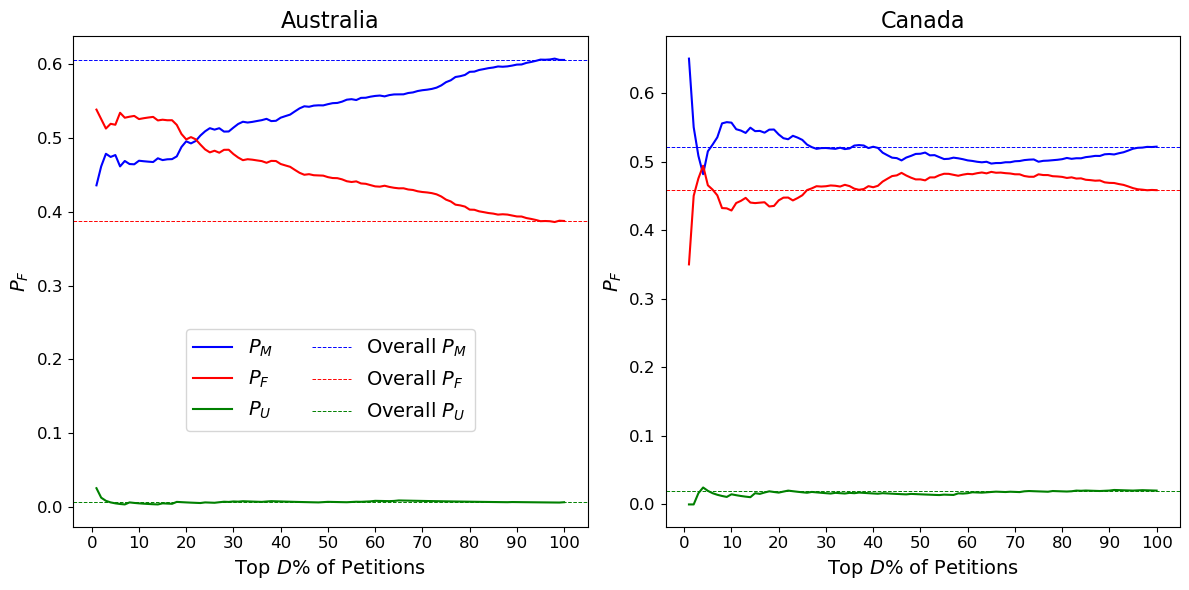

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

plot_sliced_gen_df2(axs[0], sliced_gen_df_aus, title_in = 'Australia')
plot_sliced_gen_df2(axs[1], sliced_gen_df_can, title_in = 'Canada', legend_show = False)

plt.tight_layout()

# plt.savefig('../figures/top-r-gen-aus-can-12by6-D2.png', dpi = 300, bbox_inches='tight')
plt.show()

### 3.3 Gender-Signature Plots with Covid-era Petitions Removed - Australia Only

In [20]:
def non_covid_plots2(epets_in, covid_start, covid_end, title):
    non_covid_ids = []
    epets = {}
    for k in epets_in.keys():
        dt = epets_in[k]['date']
        if dt < covid_start or dt > covid_end:
        #if covid_start <= dt <= covid_end:
            non_covid_ids.append(k)
            epets[k] = epets_in[k]
    
    # Descending order by signatures, tie-break by date, then tie-break with ID (lower ID first)
    gen_sig_df = pd.DataFrame(epets).T.reset_index().rename(columns={'index': 'id'}).sort_values(by = ['date', 'id'], ascending = [True, True])
    gen_sig_df = gen_sig_df.sort_values(by = ['signatures', 'date', 'id'], ascending = [False, True, True]) # CHANGE BACK TO FALSE, TRUE, TRUE
    gen_sig_df = gen_sig_df[['id', 'signatures', 'gender']]
    gen_dict_sorted = dict(zip(gen_sig_df[['id', 'gender']].iloc[:, 0], gen_sig_df[['id', 'gender']].iloc[:, 1]))
    
    # print(gen_sig_df.groupby('gender').count())
    sliced_gen_df = sliced_gen_df_pipeline(gen_dict_sorted)

    fig, axs = plt.subplots(1, 1, figsize=(10, 8))
    plot_sliced_gen_df2(axs, sliced_gen_df, title)
    plt.tight_layout()
    # plt.savefig('../figures/aus-topr-no-covid-D2.png', dpi = 300, bbox_inches='tight')
    plt.show()

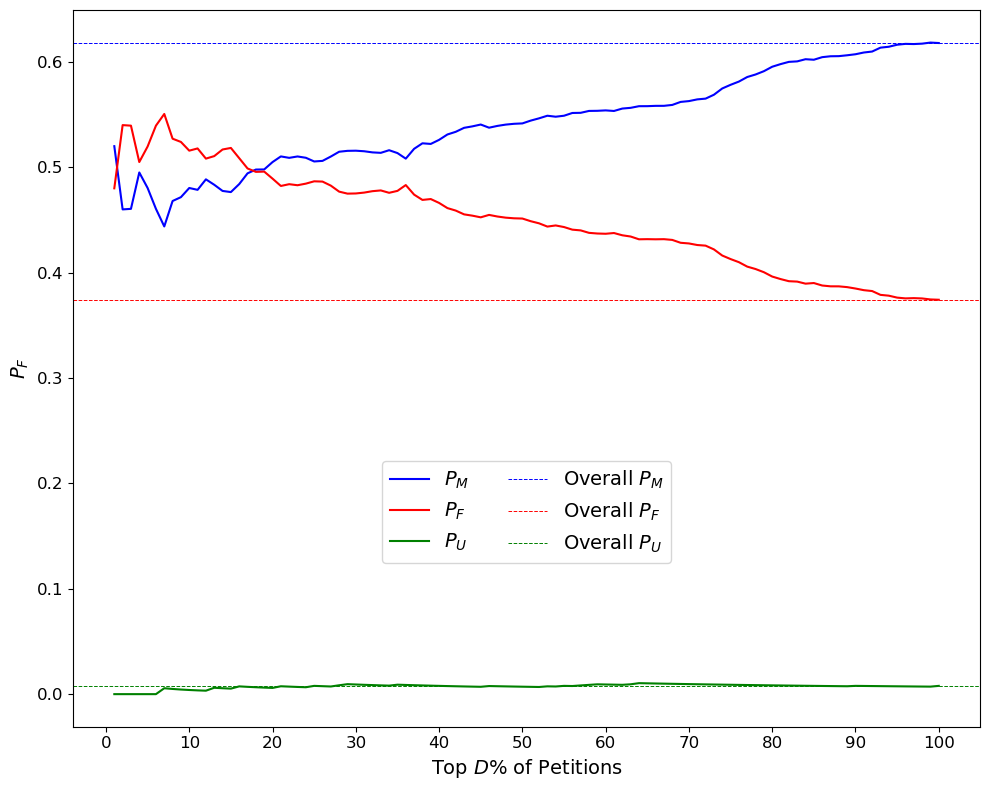

In [21]:
non_covid_plots2(aus, covid_start, covid_end, '')

### Removing period of peak female activity

In [22]:
def sliding_window_medians(data, window_size = 100, step = 10): #, sort_list = False
    # Create the windows
    windows = [data[i:i + window_size] for i in range(0, len(data) - window_size + 1, step)]
    if len(data) % step != 0: # final window will be the last 100 values with a smaller step value between it and the penultimate window
        windows.append(data[-window_size:])
        
#     # for fields like signature, we need to sort the list, for dates we want to preserve the chronological order
#     if sort_list:
#         windows = [w.sort() for w in windows]
        
    # Get the median window value for each window
    import statistics
    window_median_list = [statistics.median_low(w) for w in windows] # returns lowest of 2 middle points

    return window_median_list

def sliding_window(data, window_size = 100, step = 10): 
    windows = [data[i:i + window_size] for i in range(0, len(data) - window_size + 1, step)]
    if len(data) % step != 0: # final window will be the last 100 values with a smaller step value between it and the penultimate window
        windows.append(data[-window_size:])
    return windows

In [23]:
def non_fem_peak_plots(epets_in):
    non_peak_ids = []
    peak_start = datetime(2019, 11, 1, 0, 0, 0)
    peak_end = datetime(2021, 6, 1, 0, 0, 0)

#     peak_start = datetime(2019, 10, 1, 0, 0, 0)
#     peak_end = datetime(2021, 9, 1, 0, 0, 0)

    epets = {}
    for k in epets_in.keys():
        dt = epets_in[k]['date']
        if dt < peak_start or dt > peak_end:
        #if peak_start <= dt <= peak_end:
            non_peak_ids.append(k)
            epets[k] = epets_in[k]
    
    # Descending order by signatures, tie-break by date, then tie-break with ID (lower ID first)
    gen_sig_df = pd.DataFrame(epets).T.reset_index().rename(columns={'index': 'id'}).sort_values(by = ['date', 'id'], ascending = [True, True])
    gen_sig_df = gen_sig_df.sort_values(by = ['signatures', 'date', 'id'], ascending = [False, True, True]) # CHANGE BACK TO FALSE, TRUE, TRUE
    gen_sig_df = gen_sig_df[['id', 'signatures', 'gender']]
    gen_dict_sorted = dict(zip(gen_sig_df[['id', 'gender']].iloc[:, 0], gen_sig_df[['id', 'gender']].iloc[:, 1]))
    print(gen_sig_df.groupby('gender').count())
    
    sliced_gen_df = sliced_gen_df_pipeline(gen_dict_sorted)
    plot_sliced_gen_df(sliced_gen_df)

                 id  signatures
gender                         
female         1130        1130
male           1806        1806
unknown/other    25          25


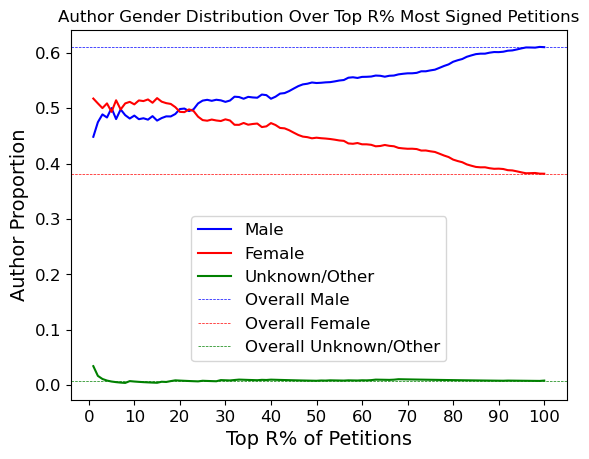

In [24]:
non_fem_peak_plots(aus)

## 4. Proportion of all female-authored (and then male-authored) petitions that occured in covid-period - Australia Only

In [25]:
def prop_aus_covid_era_pets(epets, gen_df, covid_start, covid_end):
    non_covid_ids = []
    covid_ids = []
    
    for k in epets.keys():
        dt = epets[k]['date']
        #print(dt)
        if dt < covid_start or dt > covid_end:
            non_covid_ids.append(k)
        else:
            covid_ids.append(k)
            
    total_prop = gen_df.copy()
    total_prop = total_prop[total_prop['id'].isin(non_covid_ids)]
    total_prop = total_prop[total_prop['gender'] == 'female']

    total_covid_prop = gen_df.copy()
    total_covid_prop = total_covid_prop[total_covid_prop['id'].isin(covid_ids)]
    total_covid_prop = total_covid_prop[total_covid_prop['gender'] == 'female']
    
    print(len(total_covid_prop) + len(total_prop))

    print(len(total_covid_prop)/len(gen_df[gen_df['gender'] == 'female']))
    
    total_prop = gen_df.copy()
    total_prop = total_prop[total_prop['id'].isin(non_covid_ids)]
    total_prop = total_prop[total_prop['gender'] == 'male']

    total_covid_prop = gen_df.copy()
    total_covid_prop = total_covid_prop[total_covid_prop['id'].isin(covid_ids)]
    total_covid_prop = total_covid_prop[total_covid_prop['gender'] == 'male']
    
    print(len(total_covid_prop) + len(total_prop))

    print(len(total_covid_prop)/len(gen_df[gen_df['gender'] == 'male']))

In [26]:
prop_aus_covid_era_pets(aus, gen_df_aus, covid_start, covid_end)

1514
0.36988110964332893
2366
0.3343195266272189


## 5. Mood's median test 

1. Overall male-female median comparison for Australia and Canada
2. Australia - look at pre, during, post Covid periods --> male-female median test in each of these 3 periods

### 5.1 Overall Mood's median test between male and female-authored petitions

In [27]:
def overall_gender_med_test(epets):
    # updated - needed to exclude unknown/other petitions
    sigs = [epets[k]['signatures'] for k in epets.keys() if epets[k]['gender'] in ['male', 'female']]
    print(f"Overall median of male/female-authored petitions: {np.median(sigs)}")
    
    l1 = [epets[k]['signatures'] for k in epets.keys() if epets[k]['gender'] == 'female' ]
    print(f"Median of female-authored petitions: {np.median(l1)}")
    
    l2 = [epets[k]['signatures'] for k in epets.keys() if epets[k]['gender'] == 'male' ]
    print(f"Median of male-authored petitions: {np.median(l2)}")
    
    
    print(median_test(l1, l2))

In [28]:
overall_gender_med_test(aus)

Overall median of male/female-authored petitions: 29.0
Median of female-authored petitions: 48.0
Median of male-authored petitions: 23.0
MedianTestResult(statistic=58.754435985686754, pvalue=1.7863035922607796e-14, median=29.0, table=array([[ 872, 1063],
       [ 642, 1303]]))


In [29]:
overall_gender_med_test(can)

Overall median of male/female-authored petitions: 778.0
Median of female-authored petitions: 819.5
Median of male-authored petitions: 758.0
MedianTestResult(statistic=1.3072342098417016, pvalue=0.2528960279074046, median=778.0, table=array([[479, 517],
       [453, 544]]))


### 5.2 Pre-, during-, and post-covid male/female median differences in Aus

In [30]:
pre_covid = []
covid = []
post_covid = []

for k in aus.keys():
        dt = aus[k]['date']
        if dt < covid_start:
            pre_covid.append(k)
        elif dt > covid_end:
            post_covid.append(k)
        elif covid_start <= dt <= covid_end:
            covid.append(k)

non_covid = [k for k in aus.keys() if k not in covid]

pre_covid_sigs = [aus[k]['signatures'] for k in pre_covid]
pre_covid_sigs_f = [aus[k]['signatures'] for k in pre_covid if aus[k]['gender'] == 'female']
print(f"Median of female-authored petitions: {np.median(pre_covid_sigs_f)}")
pre_covid_sigs_m = [aus[k]['signatures'] for k in pre_covid if aus[k]['gender'] == 'male']
print(f"Median of male-authored petitions: {np.median(pre_covid_sigs_m)}")

covid_sigs = [aus[k]['signatures'] for k in covid]
covid_sigs_f = [aus[k]['signatures'] for k in covid if aus[k]['gender'] == 'female']
print(f"Median of female-authored petitions: {np.median(covid_sigs_f)}")
covid_sigs_m = [aus[k]['signatures'] for k in covid if aus[k]['gender'] == 'male']
print(f"Median of male-authored petitions: {np.median(covid_sigs_m)}")


post_covid_sigs = [aus[k]['signatures'] for k in post_covid]
post_covid_sigs_f = [aus[k]['signatures'] for k in post_covid if aus[k]['gender'] == 'female']
print(f"Median of female-authored petitions: {np.median(post_covid_sigs_f)}")
post_covid_sigs_m = [aus[k]['signatures'] for k in post_covid if aus[k]['gender'] == 'male']
print(f"Median of male-authored petitions: {np.median(post_covid_sigs_m)}")


non_covid_sigs = [aus[k]['signatures'] for k in non_covid]
non_covid_sigs_f = [aus[k]['signatures'] for k in non_covid if aus[k]['gender'] == 'female']
print(f"Median of female-authored petitions: {np.median(non_covid_sigs_f)}")
non_covid_sigs_m = [aus[k]['signatures'] for k in non_covid if aus[k]['gender'] == 'male']
print(f"Median of male-authored petitions: {np.median(non_covid_sigs_m)}")

print(len(pre_covid_sigs))
print(len(covid_sigs))
print(len(post_covid_sigs))
print(len(non_covid_sigs))

print(median_test(pre_covid_sigs_f, pre_covid_sigs_m))

print(median_test(covid_sigs_f, covid_sigs_m))

print(median_test(post_covid_sigs_f, post_covid_sigs_m))

print(median_test(non_covid_sigs_f, non_covid_sigs_m))

Median of female-authored petitions: 48.0
Median of male-authored petitions: 15.0
Median of female-authored petitions: 49.0
Median of male-authored petitions: 32.0
Median of female-authored petitions: 44.0
Median of male-authored petitions: 22.0
Median of female-authored petitions: 46.0
Median of male-authored petitions: 20.0
787
1357
1762
2549
MedianTestResult(statistic=35.016310680485354, pvalue=3.269550623893097e-09, median=23.0, table=array([[193, 198],
       [112, 281]]))
MedianTestResult(statistic=5.878442746295974, pvalue=0.01532737213626416, median=37.0, table=array([[301, 371],
       [259, 420]]))
MedianTestResult(statistic=31.084128579936145, pvalue=2.4708347760332213e-08, median=28.0, table=array([[377, 484],
       [272, 612]]))
MedianTestResult(statistic=63.95437511514129, pvalue=1.273342159977776e-15, median=27.0, table=array([[571, 683],
       [383, 892]]))


## 6. Check metadata topics

1. Linear model of log(median sig) vs proportion of female authors - only consider topics with >= 20
2. Look at top 10 most popular topics - exclude any topics where f_author_prop > overall f_author_prop. Then, rerun Mood's median test and look at plot

In [31]:
# # 1. Find topics which have >=10 entries in the whole dataset
# filter_group = dict(Counter([aus[k]['metadata_theme'] for k in aus.keys() if aus[k]['metadata_theme'] != None]))
# filter_group = {k:v for k,v in filter_group.items() if v >= 10}
# filter_group = list(filter_group.keys())
# #filter_group

In [32]:
fem_prop = len([k for k in aus.keys() if aus[k]['gender'] == 'female'])/len(aus)
print(fem_prop)

0.3876088069636457


In [33]:
# find median sig + female proportion for each topic
def create_theme_mediansig_fprop_df(theme_list, epets):
    theme_sigs = {}
    theme_fcount = {}
    d = {'theme': [], 'median_sig': [], 'total_sig' :[], 'fprop': [], 'count': [], 'count_female': []}
    
    for theme in theme_list:
        d['theme'].append(theme)
        
        all_pets_gen = [epets[k]['gender'] for k in epets.keys() if epets[k]['metadata_theme'] == theme]
        d['count'].append(len(all_pets_gen))
        d['count_female'].append(len([x for x in all_pets_gen if x == 'female']))
        
        all_pets = [epets[k]['signatures'] for k in epets.keys() if epets[k]['metadata_theme'] == theme]
        fprop = len([k for k in epets.keys() if epets[k]['gender'] == 'female' and epets[k]['metadata_theme'] == theme])/len(all_pets)
        d['fprop'].append(fprop) 
        
        if len(all_pets) != 0:
            d['median_sig'].append(np.median(all_pets))
            d['total_sig'].append(sum(all_pets))
        else:
            d['median_sig'].append(None)
            d['total_sig'].append(0)
        
        df = pd.DataFrame(d).sort_values(by = 'median_sig', ascending = False)

    return df

In [34]:
filter_group = dict(Counter([aus[k]['metadata_theme'] for k in aus.keys() if aus[k]['metadata_theme'] != None]))
theme_list = [k for k,v in filter_group.items() if v >= 20]
print('List of themes: all themes in the dataset with >=20 petitions associated to them. Excluding "None"')

df_testing = create_theme_mediansig_fprop_df(theme_list, aus)
df_testing['median_sig_log'] = np.log(df_testing['median_sig'])
df_testing = df_testing[df_testing['theme'] != None]

List of themes: all themes in the dataset with >=20 petitions associated to them. Excluding "None"


In [35]:
# CANADA
filter_group = dict(Counter([can[k]['metadata_theme'] for k in can.keys() if can[k]['metadata_theme'] != None]))
theme_list = [k for k,v in filter_group.items() if v >= 20]
print('List of themes: all themes in the dataset with >=20 petitions associated to them. Excluding "None"')

df_testing_can = create_theme_mediansig_fprop_df(theme_list, can)
df_testing_can['median_sig_log'] = np.log(df_testing_can['median_sig'])
df_testing_can = df_testing_can[df_testing_can['theme'] != None]

List of themes: all themes in the dataset with >=20 petitions associated to them. Excluding "None"


## Figure 3

In [36]:
## Plotting code as a function:
fem_prop = len([k for k in can.keys() if can[k]['gender'] == 'female'])/len(can)
print(fem_prop)

def plot_gen_prop_topics_can(ax, country, epets, df_testing, fem_prop):
    #fig, ax = plt.subplots(figsize=(10, 10))

    x = df_testing['fprop'].values
    y = df_testing['median_sig_log'].values
    labels = df_testing['theme'].values
    sizes = df_testing['count'].values
    shading = np.log(df_testing['total_sig'].values)

    ax.scatter(
        x, y,
        c=shading,
        cmap='Oranges',
        edgecolor='red',
        s=sizes,
        lw=0.7)

    
    # Put labels directly at their points initially
    texts = [ax.text(
            x[i], y[i],
            labels[i],
            fontsize=16) for i in range(len(x))] # was 14

#     if country == 'Canada':
#         ax.margins(x=0.15, y=0.15)
    
    adjust_text(
        texts,
        x=x,
        y=y,
        ax=ax,

        # stronger label-label repulsion
        force_text=(0.8, 1.0),

        # push labels away from data points
        force_static=(0.5, 0.8),

        # allow labels to move sufficiently far
        max_move=(80, 80), # was 50, 50 

        # add padding around labels
        expand=(1.15, 1.3),
        
        ensure_inside_axes=True,

        arrowprops=dict(
            arrowstyle='->',
            color='grey',
            lw=0.5
        )
    )

    ax.axhline(
        y=np.log(np.median([epets[k]['signatures'] for k in epets.keys()])),
        color='blue', # was cornflowerblue
        linestyle='--',
        linewidth=0.8,
        label=r'Overall $ln(\tilde{s})$' 
    )

    ax.axvline(
        x=fem_prop,
        color='g',
        linestyle='--',
        linewidth=0.8,
        label=r'Overall $P_{F}$'
    )

    ax.tick_params(axis='both', which='major', labelsize=16)

    ax.set_ylabel(r'$ln(\tilde{s})$', fontsize=18)
    ax.set_xlabel(r'$P_{F}$', fontsize=18)

    ax.legend(fontsize=18, loc='upper left')
    
    return ax
    

def plot_fem_prop_over_time_generic(ax, ordered_date_list, ordered_gen_list, covid_start, covid_end, title_in = None):
    median_window_dates = sliding_window_medians(ordered_date_list, window_size = 100, step = 10)
    
    gender_windows = sliding_window(ordered_gen_list, window_size = 100, step = 10)
    median_window_fem_prop = [len([x for x in w if x == 'female'])/len(w) for w in gender_windows]

    #print(len(median_window_dates))
    #print(len(median_window_fem_prop))
    #import matplotlib.pyplot as plt
    #fig, ax = plt.subplots(figsize=(10, 10))
    
    ax.plot(median_window_dates, median_window_fem_prop, color = 'black')
    ax.axvspan(covid_start, covid_end, color='gray', alpha=0.3, label = 'COVID Period')

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    ax.tick_params(axis='y', labelsize=16)
    ax.tick_params(axis='x', labelsize=16)
#     ax.set_xticklabels(ax.get_xticks(), fontsize=12)
#     ax.set_yticklabels(ax.get_yticks(), fontsize=12)
    
    if title_in != None:
        ax.set_title(title_in, fontsize = 24)
#     else:
#         ax.set_title("Proportion of Female-Authored Petitions Over Time", fontsize = 18)
    
    ax.set_xlabel("Time", fontsize = 18, labelpad=15)
    ax.set_ylabel(r'$P_{F}$', fontsize = 18, labelpad=5)
    ax.set_ylim(0.2, 0.7)
    ax.legend(loc='upper left', fontsize = 20)
    
    return ax


0.4582104228121927


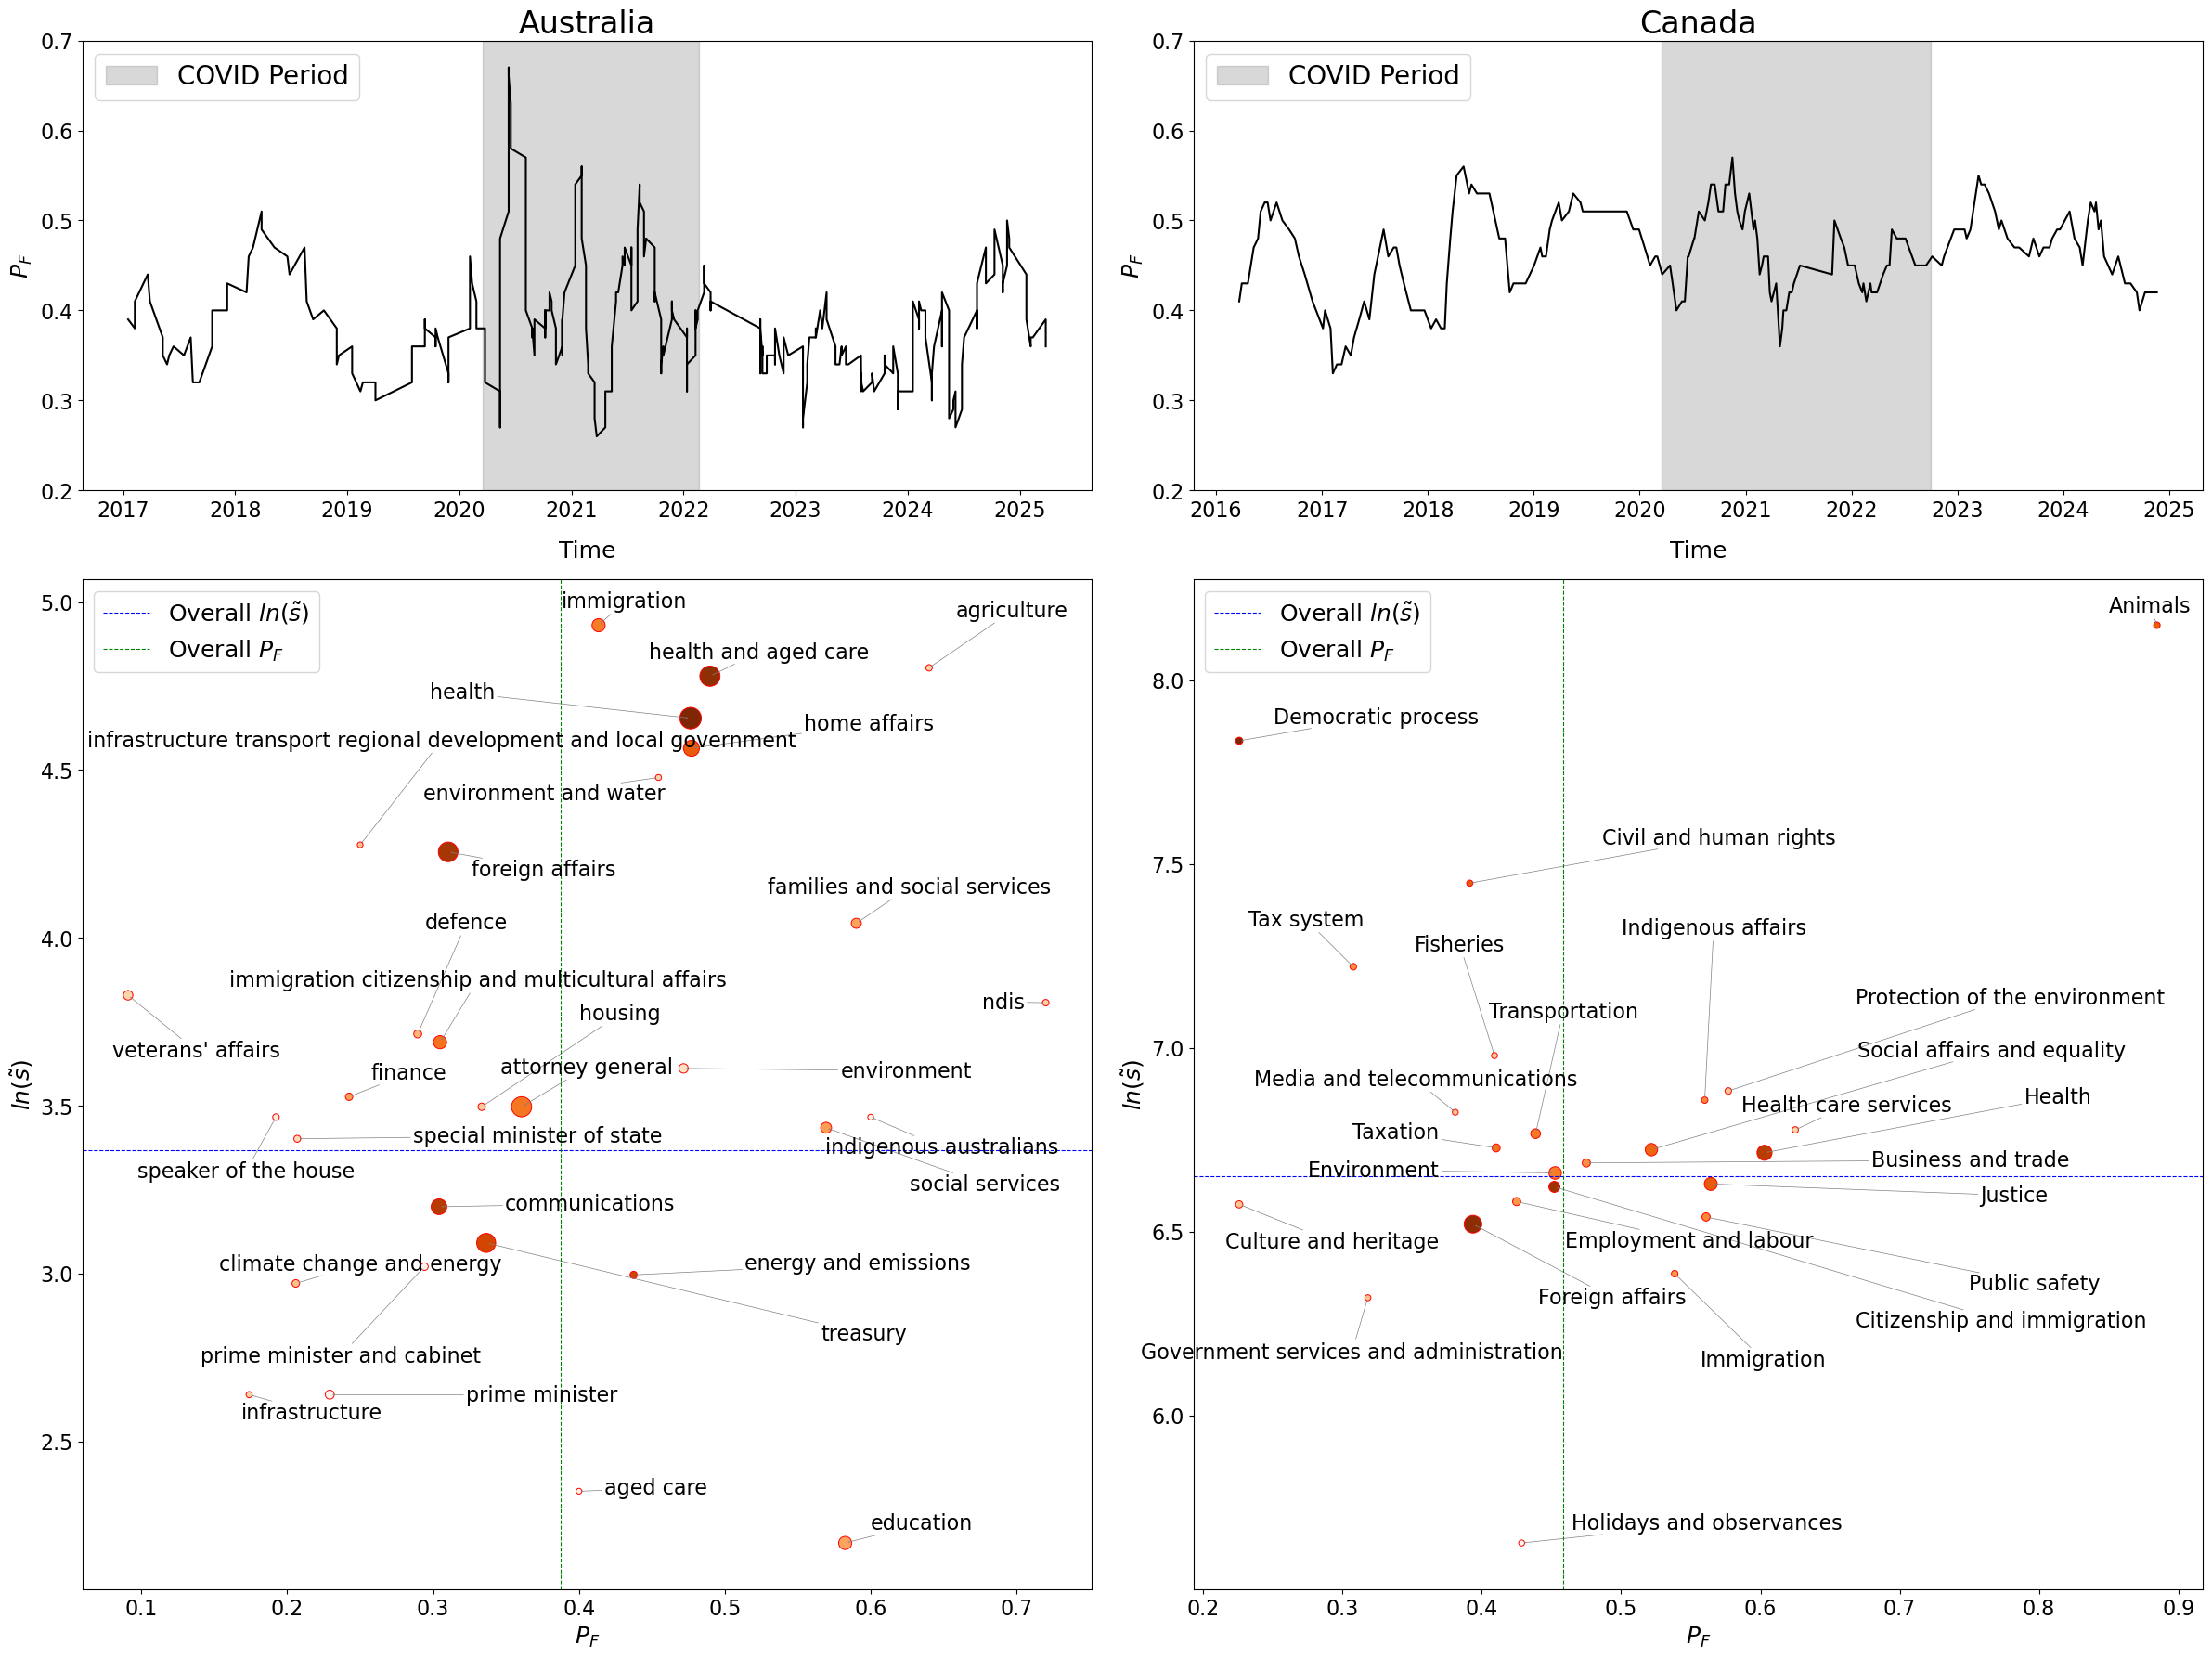

In [37]:
fem_prop = len([k for k in aus.keys() if aus[k]['gender'] == 'female'])/len(aus)
fem_prop_can = len([k for k in can.keys() if can[k]['gender'] == 'female'])/len(can)

fig, axs = plt.subplots(
    2, 2,
    figsize=(24, 18), # 20, 16
    gridspec_kw={'height_ratios': [0.6, 1.4]}
)

# Top row: plot type A
plot_fem_prop_over_time_generic(axs[0, 0], list(chron_df_aus['date']), list(chron_df_aus['gender']), covid_start, covid_end, title_in = 'Australia')
plot_gen_prop_topics_can(axs[1, 0], 'Australia', aus, df_testing, fem_prop)
#plot_gen_prop_topics_aus(axs[0, 1], df_testing, fem_prop)

# Bottom row: plot type B
plot_fem_prop_over_time_generic(axs[0, 1], list(chron_df_can['date']), list(chron_df_can['gender']), covid_start_can, covid_end_can, title_in = 'Canada')
plot_gen_prop_topics_can(axs[1, 1], 'Canada', can, df_testing_can, fem_prop_can)

# Make bottom plots square
axs[1, 0].set_box_aspect(1)
axs[1, 1].set_box_aspect(1)

plt.tight_layout()
# plt.savefig('../figures/fem-prop-time-topics-aus-can-resized3.png', dpi = 300, bbox_inches='tight')
plt.show()

In [38]:
## LINEAR RELATIONSHIP ASSESSMENT
import scipy.stats as stats
def check_lin(df_testing):
    x = df_testing['fprop'].values
    y = df_testing['median_sig_log'].values
    slope, intercept, r, p, se = stats.linregress(x, y)
    print(f"R: {r:.3f}")
    print(f"R2: {r**2:.3f}")
    print(f"R2 percentage: {(r**2)*100:.3f}")
    print(f"P value: {p:.3f}")
    n = len(x)
    from scipy.stats import t
    tinv = lambda p, df: abs(t.ppf(p/2, df))
    ts = tinv(0.05, n-2) 
    print(f"slope (se) [CI]: {slope:.3f} ({se:.3f}) [{slope - ts*se:.3f}, {slope + ts*se:.3f}]")
        
check_lin(df_testing)
check_lin(df_testing_can)

R: 0.275
R2: 0.076
R2 percentage: 7.557
P value: 0.141
slope (se) [CI]: 1.282 (0.847) [-0.454, 3.017]
R: 0.198
R2: 0.039
R2 percentage: 3.934
P value: 0.353
slope (se) [CI]: 0.694 (0.731) [-0.822, 2.210]


In [39]:
## FIND MIN AND MAX

def min_max(df_testing, field):
    l = df_testing[field].values
    
    print(field)
    print(f"Minimum: {min(l)}")
    print(f"Maximum: {max(l)}")
    
    
min_max(df_testing, 'fprop')
min_max(df_testing_can, 'fprop')

fprop
Minimum: 0.09090909090909091
Maximum: 0.72
fprop
Minimum: 0.22580645161290322
Maximum: 0.8846153846153846


In [40]:
from collections import Counter
# print(Counter(pd.DataFrame(aus).T['metadata_theme']))

print(len(aus) - dict(Counter(pd.DataFrame(aus).T['metadata_theme']))[None])

print((len(aus) - dict(Counter(pd.DataFrame(aus).T['metadata_theme']))[None])/len(aus)*100)

2975
76.16487455197132


### Exclude most popular themes were the theme's female proportion value is higher than the whole dataset female proportion calue

In [41]:
top10 = df_testing.nlargest(10, 'count')
print(top10)

themes_to_exclude = top10.loc[top10['fprop'] > fem_prop, 'theme'].tolist()
print(themes_to_exclude)

                                                theme  median_sig  total_sig  \
9                                              health       105.0    1598801   
26                               health and aged care       119.0    1141567   
2                                    attorney general        33.0     127762   
3                                     foreign affairs        70.5     748878   
8                                            treasury        22.0     387481   
16                                       home affairs        96.0     232203   
0                                      communications        24.5     609512   
21  immigration citizenship and multicultural affairs        40.0     136314   
6                                         immigration       138.5     112201   
19                                          education         9.0      45884   

       fprop  count  count_female  median_sig_log  
9   0.476534    277           132        4.653960  
26  0.489796   

In [42]:
# print(len(df_testing))

3024


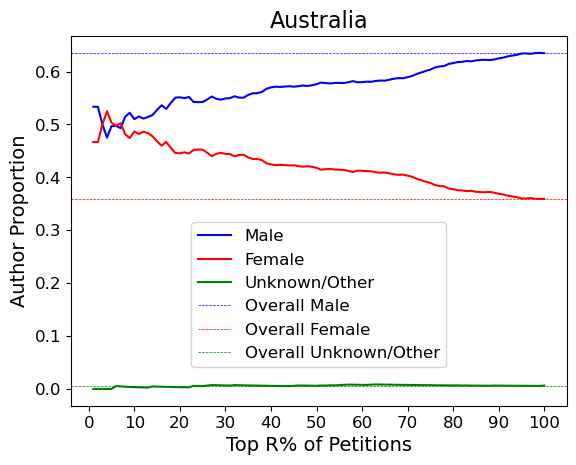

Overall median of male/female-authored petitions: 25.0
Median of female-authored petitions: 35.0
Median of male-authored petitions: 20.0
MedianTestResult(statistic=45.2296290883653, pvalue=1.7523380346513213e-11, median=25.0, table=array([[ 625,  858],
       [ 461, 1061]]))


In [43]:
def exclusion_pipeline(exclude_list, epets, exclude_flag = True):
    if exclude_flag == True:
        epets_new = {k:v for k,v in epets.items() if epets[k]['metadata_theme'] not in exclude_list}
    
    else:
        epets_new = {k:v for k,v in epets.items() if epets[k]['metadata_theme'] in exclude_list}
        
    
    print(len(epets_new))
    
    # re-look at plot
    chron_df_aus, gen_df_aus, gen_sig_df_aus, gen_dict_sorted_aus, gen_date_sig_aus, df_gds_wide_aus, pivoted_aus, epet_dates_aus, sig_list_chron_aus = creating_dfs_dicts(epets_new)
    sliced_gen_df_aus = sliced_gen_df_pipeline(gen_dict_sorted_aus)
    plot_sliced_gen_df(sliced_gen_df_aus, out_file = None, title_in = 'Australia')
    
    # re-run mood's median test
    overall_gender_med_test(epets_new)
    
exclusion_pipeline(themes_to_exclude, aus, True)

882


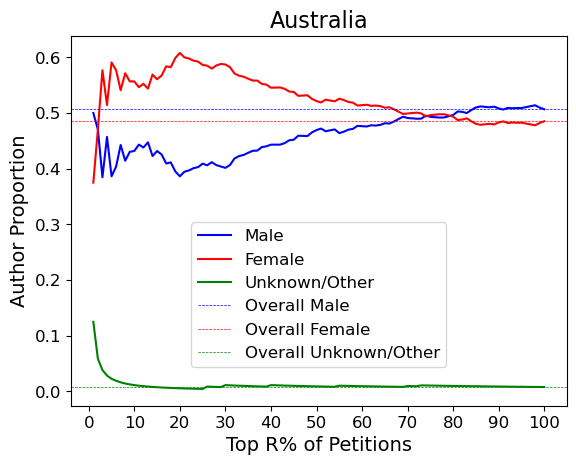

Overall median of male/female-authored petitions: 83.0
Median of female-authored petitions: 123.5
Median of male-authored petitions: 65.0
MedianTestResult(statistic=4.2336717369435295, pvalue=0.039629621124505326, median=83.0, table=array([[228, 206],
       [200, 241]]))


In [44]:
exclusion_pipeline(themes_to_exclude, aus, False)